# Korea imports of HS 2202 and Singha's company-stated Korea figures

This notebook rebuilds the Korea chart from saved data. It reads the raw UN Comtrade responses in `raw/`, builds the 2019 to 2025 table, saves that table as CSV, adds Singha's company-stated figures from `singha_company_stated.json`, and draws the chart to `korea_imports_hs2202.png`.

- Data: UN Comtrade preview API. Reporter Korea (410), partner 0 (world) and 764 (Thailand), commodity HS 2202, flow M (imports), values in USD. Retrieved 2026-10-17.
- Singha figures are company-stated and not independently verified. They appear as text, not as bars, and they are not a Singha sales series.
- HS 2202 covers sweetened or flavoured waters and other non-alcoholic beverages from all brands and origins. It is not Singha volume.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd()
RAW = HERE / "raw"
OUT_PNG = HERE / "korea_imports_hs2202.png"
OUT_CSV = HERE / "korea_hs2202_imports_2019_2025.csv"

## 1. Read the raw Comtrade responses

In [2]:
records = []
for path in sorted(RAW.glob("comtrade_410_partner*_*.json")):
    payload = json.loads(path.read_text(encoding="utf-8-sig"))
    for rec in payload["data"]:
        records.append({
            "year": rec["refYear"],
            "reporter_code": rec["reporterCode"],
            "partner_code": rec["partnerCode"],
            "flow": rec["flowCode"],
            "cmd_code": rec["cmdCode"],
            "value_usd": rec["primaryValue"],
            "source_file": path.name,
        })

raw = pd.DataFrame(records)
print(f"{len(raw)} records from {raw['source_file'].nunique()} files")
raw

14 records from 14 files


,year,reporter_code,partner_code,flow,cmd_code,value_usd,source_file
0,2019,410,0,M,2202,93605612.0,comtrade_410_partner0_2019.json
1,2020,410,0,M,2202,88501658.0,comtrade_410_partner0_2020.json
2,2021,410,0,M,2202,116911558.0,comtrade_410_partner0_2021.json
3,2022,410,0,M,2202,135078438.0,comtrade_410_partner0_2022.json
4,2023,410,0,M,2202,138423874.0,comtrade_410_partner0_2023.json
5,2024,410,0,M,2202,138421815.0,comtrade_410_partner0_2024.json
6,2025,410,0,M,2202,134426942.0,comtrade_410_partner0_2025.json
7,2019,410,764,M,2202,14417808.0,comtrade_410_partner764_2019.json
8,2020,410,764,M,2202,13079427.0,comtrade_410_partner764_2020.json
9,2021,410,764,M,2202,17066939.0,comtrade_410_partner764_2021.json


## 2. Build the table and check it

In [3]:
ORIGIN = {0: "all_origins", 764: "thailand"}
raw["origin"] = raw["partner_code"].map(ORIGIN)
assert raw["origin"].notna().all(), "unexpected partner code"
assert (raw["reporter_code"] == 410).all(), "unexpected reporter"
assert (raw["cmd_code"].astype(str) == "2202").all(), "unexpected commodity"
assert (raw["flow"] == "M").all(), "unexpected flow"

usd = raw.pivot(index="year", columns="origin", values="value_usd").sort_index()
assert list(usd.index) == list(range(2019, 2026)), "years missing"
assert usd.notna().all().all(), "missing values"

table = pd.DataFrame({
    "all_origins_usd": usd["all_origins"],
    "thailand_usd": usd["thailand"],
    "all_origins_musd": (usd["all_origins"] / 1e6).round(1),
    "thailand_musd": (usd["thailand"] / 1e6).round(1),
})
table.to_csv(OUT_CSV)
table

,all_origins_usd,thailand_usd,all_origins_musd,thailand_musd
year,,,,
2019,93605612.0,14417808.0,93.6,14.4
2020,88501658.0,13079427.0,88.5,13.1
2021,116911558.0,17066939.0,116.9,17.1
2022,135078438.0,21443042.0,135.1,21.4
2023,138423874.0,25726556.0,138.4,25.7
2024,138421815.0,21740569.0,138.4,21.7
2025,134426942.0,19583267.0,134.4,19.6


## 3. Derived changes used in the chart caption

In [4]:
def pct(a, b):
    return (b / a - 1) * 100

thai = usd["thailand"]
allo = usd["all_origins"]
changes = {
    "thailand_2023_to_2025_pct": pct(thai[2023], thai[2025]),
    "all_origins_2023_to_2025_pct": pct(allo[2023], allo[2025]),
    "thailand_2019_to_2025_pct": pct(thai[2019], thai[2025]),
    "all_origins_2019_to_2025_pct": pct(allo[2019], allo[2025]),
}
for key, value in changes.items():
    print(f"{key}: {value:+.1f}%")

thailand_2023_to_2025_pct: -23.9%
all_origins_2023_to_2025_pct: -2.9%
thailand_2019_to_2025_pct: +35.8%
all_origins_2019_to_2025_pct: +43.6%


## 4. Singha company-stated figures (text only)

In [5]:
singha = json.loads((HERE / "singha_company_stated.json").read_text(encoding="utf-8"))
singha["figures"]

{'share_in_korea_2020_pct': 5.7,
 'share_in_korea_2024_pct': 15.4,
 'soda_sales_2024_vs_2023_multiple': 2.0,
 'sales_target_2025_multiple': 6,
 'sales_target_base_year': None,
 'korea_soda_market_2025_m_litres': 29.1,
 'korea_soda_market_growth_pct_per_year': 28}

## 5. Chart (grayscale, no color)

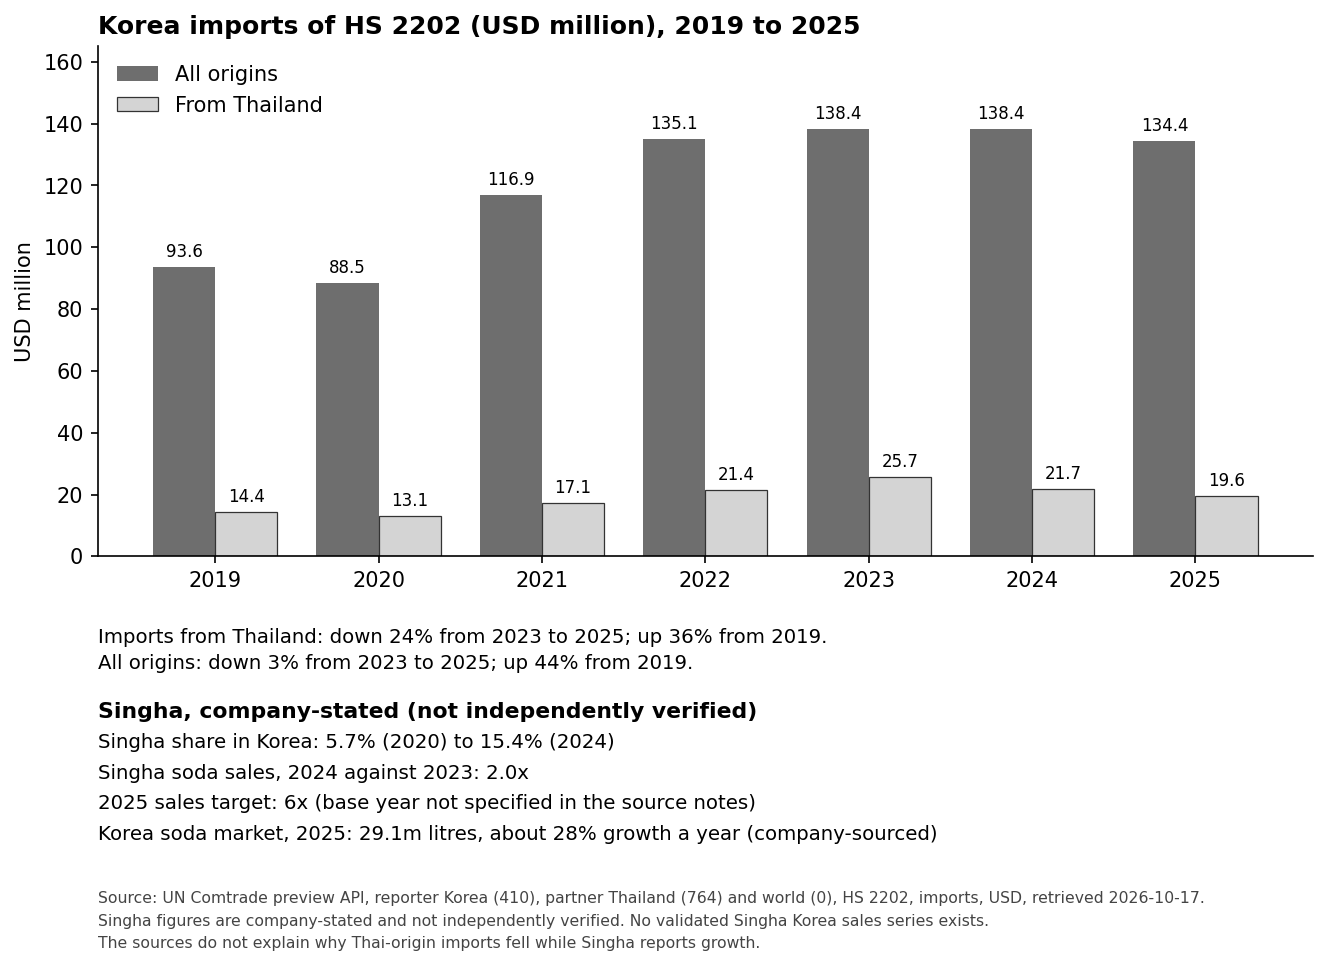

In [6]:
years = table.index.tolist()
x = np.arange(len(years))
w = 0.38

fig = plt.figure(figsize=(9, 6.8), dpi=150, facecolor="white")
ax = fig.add_axes([0.08, 0.42, 0.90, 0.50])
b1 = ax.bar(x - w / 2, table["all_origins_musd"], w, color="#6e6e6e", label="All origins")
b2 = ax.bar(x + w / 2, table["thailand_musd"], w, color="#d4d4d4", edgecolor="#333333", linewidth=0.6, label="From Thailand")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 2, f"{r.get_height():.1f}",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [str(y) for y in years])
ax.set_ylim(0, 165)
ax.set_ylabel("USD million")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Korea imports of HS 2202 (USD million), 2019 to 2025", loc="left", fontsize=12, fontweight="bold")

def rounded(key):
    return round(changes[key])

fig.text(0.08, 0.335,
         f"Imports from Thailand: down {abs(rounded('thailand_2023_to_2025_pct'))}% from 2023 to 2025; "
         f"up {rounded('thailand_2019_to_2025_pct')}% from 2019.", fontsize=9.5)
fig.text(0.08, 0.310,
         f"All origins: down {abs(rounded('all_origins_2023_to_2025_pct'))}% from 2023 to 2025; "
         f"up {rounded('all_origins_2019_to_2025_pct')}% from 2019.", fontsize=9.5)

f = singha["figures"]
fig.text(0.08, 0.262, "Singha, company-stated (not independently verified)", fontsize=10.5, fontweight="bold")
singha_lines = [
    f"Singha share in Korea: {f['share_in_korea_2020_pct']}% (2020) to {f['share_in_korea_2024_pct']}% (2024)",
    f"Singha soda sales, 2024 against 2023: {f['soda_sales_2024_vs_2023_multiple']}x",
    f"2025 sales target: {f['sales_target_2025_multiple']}x (base year not specified in the source notes)",
    f"Korea soda market, 2025: {f['korea_soda_market_2025_m_litres']}m litres, about "
    f"{f['korea_soda_market_growth_pct_per_year']}% growth a year (company-sourced)",
]
for i, t in enumerate(singha_lines):
    fig.text(0.08, 0.232 - i * 0.030, t, fontsize=9.5)

footer = [
    "Source: UN Comtrade preview API, reporter Korea (410), partner Thailand (764) and world (0), HS 2202, imports, USD, retrieved 2026-10-17.",
    "Singha figures are company-stated and not independently verified. No validated Singha Korea sales series exists.",
    "The sources do not explain why Thai-origin imports fell while Singha reports growth.",
]
for i, t in enumerate(footer):
    fig.text(0.08, 0.080 - i * 0.022, t, fontsize=7.5, color="#444444")

fig.savefig(OUT_PNG, dpi=150, facecolor="white")
plt.show()

## 6. Outputs

In [7]:
print("Written:", OUT_PNG.name, OUT_CSV.name)
table

Written: korea_imports_hs2202.png korea_hs2202_imports_2019_2025.csv


,all_origins_usd,thailand_usd,all_origins_musd,thailand_musd
year,,,,
2019,93605612.0,14417808.0,93.6,14.4
2020,88501658.0,13079427.0,88.5,13.1
2021,116911558.0,17066939.0,116.9,17.1
2022,135078438.0,21443042.0,135.1,21.4
2023,138423874.0,25726556.0,138.4,25.7
2024,138421815.0,21740569.0,138.4,21.7
2025,134426942.0,19583267.0,134.4,19.6


## Re-running

- Restart the kernel and run all cells, or run `jupyter nbconvert --to notebook --execute --inplace korea_imports_chart.ipynb` from this folder.
- Requirements: Python 3, pandas, numpy, matplotlib, and ipykernel (plus nbformat and nbconvert for the command-line run).
- The raw files in `raw/` came from `https://comtradeapi.un.org/public/v1/preview/C/A/HS` with `reporterCode=410`, `period=2019` to `2025`, `partnerCode=0` or `764`, `cmdCode=2202`, `flowCode=M`. Some calls returned HTTP 429 (rate limit) and were retried after a pause.